In [62]:
# imports to enable the notebook to access the src folder
import sys
import os
sys.path.append(os.path.dirname(os.getcwd()))

# import the necessary packages
from src.molecules import StructuralValidator
from src.pure import PropertyCalculator
from src.pure import AntoineCalculator
from src.data import load_unifac_data
from src.mixture.unifac.pyomo_iss import pyo_iss
from src.mixture.unifac.pyomo_vle import pyo_vle
import numpy as np
import matplotlib.pyplot as plt

In [63]:
# step1: define the compounds
mixture = {'acetone': {'CH3':1, 'CH3CO':1},
           'methanol': {'CH3OH':1},
           #'water': {'H2O':1}
           'DOH': {'DOH':1}
           #'DMSO': {'DMSO':1}
           #'E': {'CH3':2, 'CH2':1, 'C':1, 'CH3CO':2}
           #'E': {'CH3':4, 'C':1, 'CH2COO':1}
           }
# validate the structures
validator = StructuralValidator()
validator.validate(mixture)

{'acetone': True, 'methanol': True, 'DOH': True}

In [64]:
# step2: calculate the required properties
prop_list = ['tc', 'pc', 'tb', 'ac', 'hv']
pure_calc = PropertyCalculator()
pure_props = pure_calc.calculate(mixture, prop_list)
# fix the properties of acetone
pure_props['acetone']['tc'] = 508.1
pure_props['acetone']['pc'] = 48.0
pure_props['acetone']['tb'] = 329.3
pure_props

{'acetone': {'tc': 508.1,
  'pc': 48.0,
  'tb': 329.3,
  'ac': 0.33226923286882887,
  'hv': 29.944},
 'methanol': {'tc': 513.0000000000005,
  'pc': 80.99999999999997,
  'tb': 337.84999999999985,
  'ac': 0.5639909999999987,
  'hv': 37.466699999999996},
 'DOH': {'tc': 719.7000000000002,
  'pc': 85.38000000000001,
  'tb': 470.44999999999993,
  'ac': 0.4868299999999998,
  'hv': 66.2575}}

In [65]:
# step3: calculate the Antoine coefficients
antoine_params = {}
antoine_calc = AntoineCalculator()
for compound, props in pure_props.items():
    results = antoine_calc.calculate_antoine_parameters(mixture, critical_properties=props, method='enthalpy_vap')
    print('optimization results was', results['termination_condition'] )
    antoine_params[compound] = {}
    antoine_params[compound]['A'] = results['A']
    antoine_params[compound]['B'] = results['B']
    antoine_params[compound]['C'] = results['C']
antoine_params

Characteristic points (T [K], P [bar]): (298.15, 0.32320416041085204), (329.3, 1.01325), (508.1, 48.0)
optimization results was optimal
Characteristic points (T [K], P [bar]): (298.15, 0.17155739283256194), (337.84999999999985, 1.01325), (513.0000000000005, 80.99999999999997)
optimization results was optimal
Characteristic points (T [K], P [bar]): (298.15, 5.680836454887759e-05), (470.44999999999993, 1.01325), (719.7000000000002, 85.38000000000001)
optimization results was optimal


{'acetone': {'A': 4.783740729661747,
  'B': 1581.8917318530048,
  'C': 1.7765481786898079},
 'methanol': {'A': 5.300323780998345,
  'B': 1653.077261894857,
  'C': -25.630942143670293},
 'DOH': {'A': 4.747093186769966,
  'B': 1728.0516357761755,
  'C': -105.98799014354736}}

Ipopt 3.14.13: halt_on_ampl_error=yes
max_iter=100000
tol=1e-06


******************************************************************************
This program contains Ipopt, a library for large-scale nonlinear optimization.
 Ipopt is released as open source code under the Eclipse Public License (EPL).
         For more information visit https://github.com/coin-or/Ipopt
******************************************************************************

This is Ipopt version 3.14.13, running with linear solver MUMPS 5.2.1.

Number of nonzeros in equality constraint Jacobian...:    22501
Number of nonzeros in inequality constraint Jacobian.:        0
Number of nonzeros in Lagrangian Hessian.............:    18722

Total number of variables............................:     5818
                     variables with only lower bounds:     4818
                variables with lower and upper bounds:      400
                     variables with only upper bounds:        0
Total number of equality co

/var/folders/5_/x5fhgj5d0252mwb_1nbb2d8r0000gp/T/ipykernel_83966/3913424940.py:65: RuntimeWarning: divide by zero encountered in divide
  ED = 1 - ((1 - (K[:, 1])) / (x[:, 0] * (K[:, 0] - K[:, 1])))


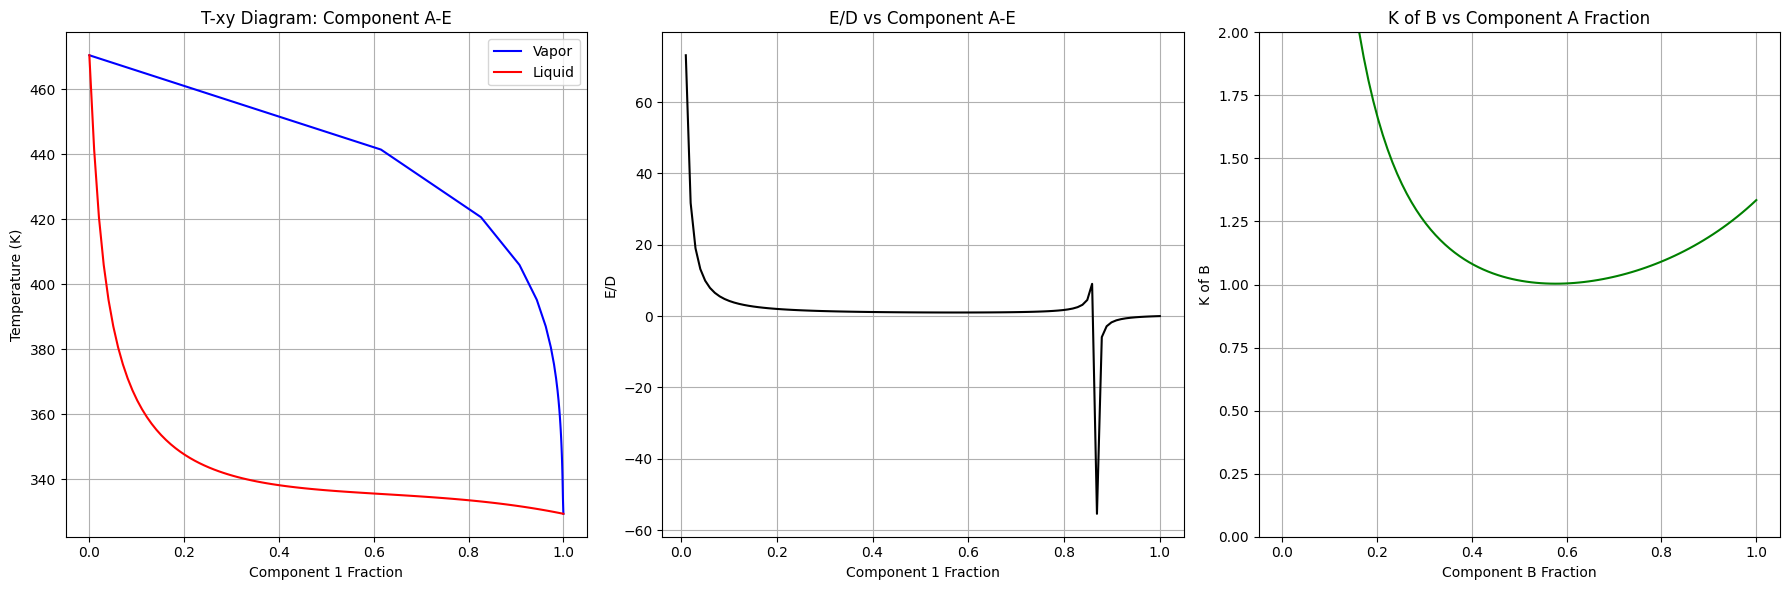

In [66]:
# step4: perform the vle

# define number of data points
n_data = 100
# set composition
# generate all binary combinations for ternary system
x0 = 0.0
xf = 1-x0

# x1-x3 binary (x2=0)
x1_13 = np.linspace(x0, xf, n_data)
x2_13 = np.zeros(n_data)
x3_13 = 1 - x1_13


# combine all binary combinations
x = np.vstack([

    np.column_stack([x1_13, x2_13, x3_13]),

])
# provide nitial guess for temperature

# Extract boiling points for each compound
tb_values = [pure_props[compound]['tb'] for compound in mixture.keys()]
tb1, tb2, tb3 = tb_values  # assuming 3 components
# Create T0 for each binary combination


# x1-x3 binary: T ranges from tb3 (x1=0, x3=1) to tb1 (x1=1, x3=0)
T0_13 = np.linspace(tb3, tb1, n_data)


# Combine all T0 values
T0 = T0_13
# Load all UNIFAC parameters
rk_data, qk_data, interaction_data = load_unifac_data()
# perform the VLE calculation
results, model = pyo_vle(x, T0, mixture, rk_data, qk_data, interaction_data, antoine_params, verbose=True)

# Extract results
# retrieving the solutions
gamma_pyo = np.empty_like(x)
T_pyo = np.empty_like(T0)
y_pyo = np.empty_like(x)
psat_pyo = np.empty_like(x)
K = np.empty_like(x)
ED = np.empty_like(T0)

for i in model.gamma.keys():
    gamma_pyo[i] = model.gamma[i].value

for i in model.T.keys():
    T_pyo[i] = model.T[i].value

for i in model.y.keys():
    y_pyo[i] = model.y[i].value

for i in model.psat.keys():
    psat_pyo[i] = model.psat[i].value

# calculate K
K = gamma_pyo * psat_pyo / 1.01325
# calculate E/D
ED = 1 - ((1 - (K[:, 1])) / (x[:, 0] * (K[:, 0] - K[:, 1])))


# Create T-xy plots for all three binary combinations and E/D vs x
# Create T-xy plots for all three binary combinations
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Component 1-2 diagram (first 100 points)
axes[0].plot(y_pyo[:n_data, 0], T_pyo[:n_data], 'b-', label='Vapor')
axes[0].plot(x[:n_data, 0], T_pyo[:n_data], 'r-', label='Liquid')
axes[0].set_ylabel('Temperature (K)')
axes[0].set_xlabel('Component 1 Fraction')
axes[0].set_title('T-xy Diagram: Component A-E')
axes[0].legend()
axes[0].grid()

# E/D vs x diagram
axes[1].plot(x[:, 0], ED, 'k-')
axes[1].set_ylabel('E/D')
axes[1].set_xlabel('Component 1 Fraction')
axes[1].set_title('E/D vs Component A-E')
axes[1].grid()

# plot K of B
axes[2].plot(x[:, 0], K[:, 1], 'g-')
axes[2].set_ylabel('K of B')
axes[2].set_xlabel('Component B Fraction')
axes[2].set_title('K of B vs Component A Fraction')
axes[2].set_ylim(0, 2)
axes[2].grid()


plt.tight_layout()
plt.show()



In [67]:
# # suggest initial values of x and T
# T0 = np.array([350,350])#np.array([(T_max + T_min) / 2, (T_max + T_min) / 2])
# #T0=np.array([ pure_props['E']['tb'], pure_props['E']['tb']])

# xA = 0.6
# x_iso = 0.7
# x0 = np.array([[x_iso, 0.0, 1-x_iso],    # Point 0: iso-volatility point
#                 [xA, 0.0, 1-xA]])          # Point 1: minimum point 
# # load unifac data
# rk_data, qk_data, interaction_data = load_unifac_data()
# #perform the VLE calculation
# resuts, model =  pyo_iss(x0, T0, mixture, rk_data, qk_data, interaction_data, antoine_params, verbose=False)

# #retrieving the solutions
# gamma = np.empty_like(x0)
# T = np.empty_like(T0)
# y = np.empty_like(x0)
# x = np.empty_like(x0)
# psat = np.empty_like(x0)


# for i in model.gamma.keys():
#     gamma[i] = model.gamma[i].value

# for i in model.T.keys():
#     T[i] = model.T[i].value

# for i in model.y.keys():
#     y[i] = model.y[i].value

# for i in model.x.keys():
#     x[i] = model.x[i].value

# for i in model.psat.keys():
#     psat[i] = model.psat[i].value

# print(model.obj())
# print(model.R.value)